In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Load anomaly and driver data
anomaly = pd.read_csv("/Users/cici/Desktop/Learning/python_work/Project_idea/fpna_variance_project/src/data_generation/data/output/anomaly.csv", parse_dates=["date"])
driver = pd.read_csv("/Users/cici/Desktop/Learning/python_work/Project_idea/fpna_variance_project/src/data_generation/data/output/driver_analysis.csv", parse_dates=["date"])

In [26]:
anomaly["region_id"].unique()

<StringArray>
['APAC', 'EU', 'OTHER']
Length: 3, dtype: str

In [28]:
f = anomaly.copy()
dr = driver.copy()

latest_date = f["date"].max()
latest = f[f["date"] == latest_date]

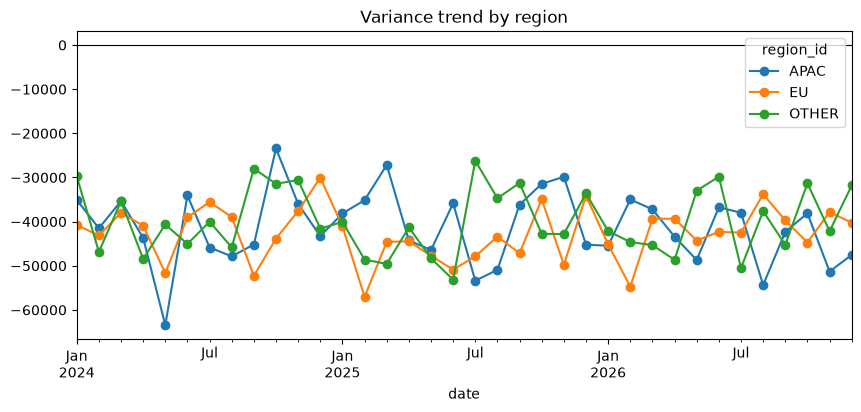

In [29]:
#Trend variance in each region
trend_region = f.pivot_table(index = "date", columns = "region_id", values = "variance", aggfunc = "sum")
trend_region.plot(marker = "o", figsize = (10, 4), title = "Variance trend by region")
plt.axhline(0, color = "black", linewidth = 0.8)
plt.show()

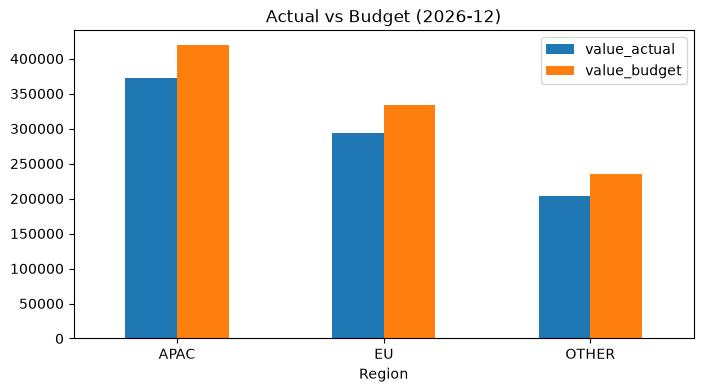

In [34]:
#Trend Actual vs Budget
trend = latest.groupby("region_id")[["value_actual", "value_budget"]].sum()
trend.plot(kind = "bar", figsize = (8, 4), title = f"Actual vs Budget ({latest_date:%Y-%m})")
plt.xticks(rotation = 0)
plt.xlabel("Region")
plt.show()

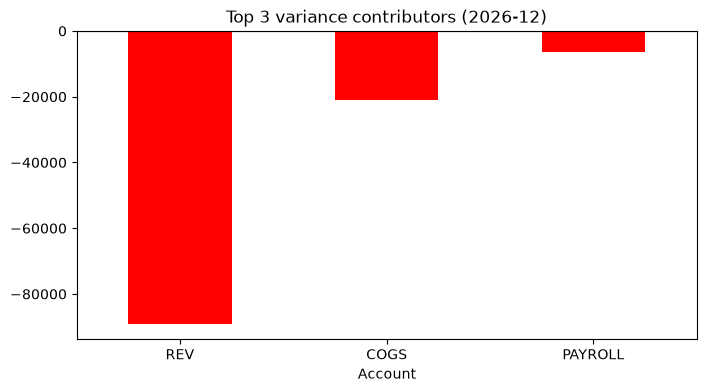

In [37]:
#Identify top 3 contributors
top = (latest.groupby("account_id", as_index = False)["variance"].sum()
       .assign(abs_var = lambda x: x["variance"].abs())
       .nlargest(3, "abs_var"))
colors = ["green" if v >= 0 else "red" for v in top["variance"]]
top.plot(kind = "bar", x = "account_id", y = "variance", color = colors, legend = False, figsize = (8, 4), title = f"Top 3 variance contributors ({latest_date:%Y-%m})")
plt.axhline(0, color = "black", linewidth = 0.8)
plt.xticks(rotation = 0)
plt.xlabel("Account")
plt.show()

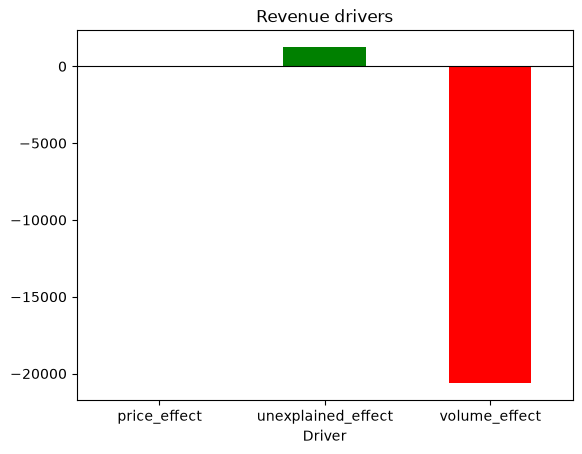

In [39]:
#Revenue driver factors
dd = dr[dr["date"] == latest_date].groupby("driver", as_index = False)["impact"].sum()
colors = ["green" if v >= 0 else "red" for v in dd["impact"]]
dd.plot(kind = "bar", x = "driver", y = "impact", color = colors, legend = False, title = "Revenue drivers")
plt.axhline(0, color = "black", linewidth = 0.8)
plt.xticks(rotation = 0)
plt.xlabel("Driver")
plt.show()

In [21]:
#Anomaly details
latest[latest["anomaly"].astype(bool)].sort_values("variance")

,Unnamed: 0,date,region_id,account_id,value_actual,value_budget,variance,variance_pct,material,rolling_mean,rolling_std,z_score,anomaly


In [24]:
f.groupby("date")["anomaly"].sum()

date
2024-01-01    0
2024-02-01    0
2024-03-01    0
2024-04-01    0
2024-05-01    2
2024-06-01    0
2024-07-01    0
2024-08-01    0
2024-09-01    0
2024-10-01    0
2024-11-01    0
2024-12-01    0
2025-01-01    0
2025-02-01    0
2025-03-01    0
2025-04-01    0
2025-05-01    0
2025-06-01    0
2025-07-01    0
2025-08-01    0
2025-09-01    0
2025-10-01    0
2025-11-01    0
2025-12-01    0
2026-01-01    0
2026-02-01    0
2026-03-01    0
2026-04-01    0
2026-05-01    0
2026-06-01    0
2026-07-01    0
2026-08-01    0
2026-09-01    0
2026-10-01    0
2026-11-01    0
2026-12-01    0
Name: anomaly, dtype: int64